# Task 1: Multi-Class Benchmark Classification Pipeline (Iris Dataset)
### End-to-End Machine Learning Pipeline: Preprocessing, Modeling, Evaluation & Decision Boundary Analysis

---

## 📋 Project Overview & Internship Objectives
- **Dataset**: Fisher's Benchmark Iris Dataset (150 samples, 4 continuous features, 3 balanced flower classes).
- **Core Requirements**:
  1. Load benchmark dataset using **Pandas** and perform Exploratory Data Analysis (**EDA**) with **Seaborn**.
  2. Implement feature scaling using **StandardScaler** ($z = \frac{x - \mu}{\sigma}$) to prevent feature dominance and gradient instability.
  3. Perform a stratified **80/20 train/test split** with strict separation to avoid data leakage.
  4. Train and benchmark two distinct supervised classification paradigms:
     - **Logistic Regression** (Linear parametric model with Multinomial Cross-Entropy loss)
     - **Decision Tree Classifier** (Non-parametric partitioning model using Gini Impurity)
  5. Benchmark performance metrics: **Accuracy, Precision, Recall, and F1-Score** (Macro & Weighted).
  6. Generate comprehensive visualizations:
     - Pairwise feature distributions (Pairplot)
     - Correlation matrix heatmap
     - Side-by-side Confusion Matrix heatmaps
     - 2D Decision Boundary visualizations comparing linear vs. orthogonal partitions
     - Visual Decision Tree diagram and Gini Feature Importance analysis


---
## Step 1: Environment Setup & Library Imports
Importing industry-standard libraries for data manipulation, visualization, model training, and performance metrics.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Preprocessing & Model Selection
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Supervised Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Plotting Configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print("All libraries successfully imported and plotting themes configured!")


All libraries successfully imported and plotting themes configured!


---
## Step 2: Data Loading & Exploratory Data Analysis (EDA)
Loading the Iris dataset from `iris.csv` and inspecting structural properties, column data types, missing value checks, and class balances.


In [2]:
# Load dataset using Pandas
csv_file = "iris.csv"
df = pd.read_csv(csv_file)

# Display dataset properties
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\n--- First 5 Samples ---")
display(df.head())

print("\n--- Dataset Information ---")
df.info()

print("\n--- Missing Values Check ---")
print(df.isnull().sum())

print("\n--- Class Balance Check ---")
print(df['species'].value_counts())


Dataset Shape: 150 rows, 5 columns

--- First 5 Samples ---


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

--- Missing Values Check ---
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

--- Class Balance Check ---
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


### Summary Statistics of Continuous Features
Examining central tendencies, spreads, and range across feature columns.


In [3]:
# Summary statistics for numeric features
display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


### Exploratory Visualization 1: Pairwise Feature Distributions (Pairplot)
Pairplot provides visual inspection of bivariate relationships and univariate class-conditional probability density estimates (KDE).


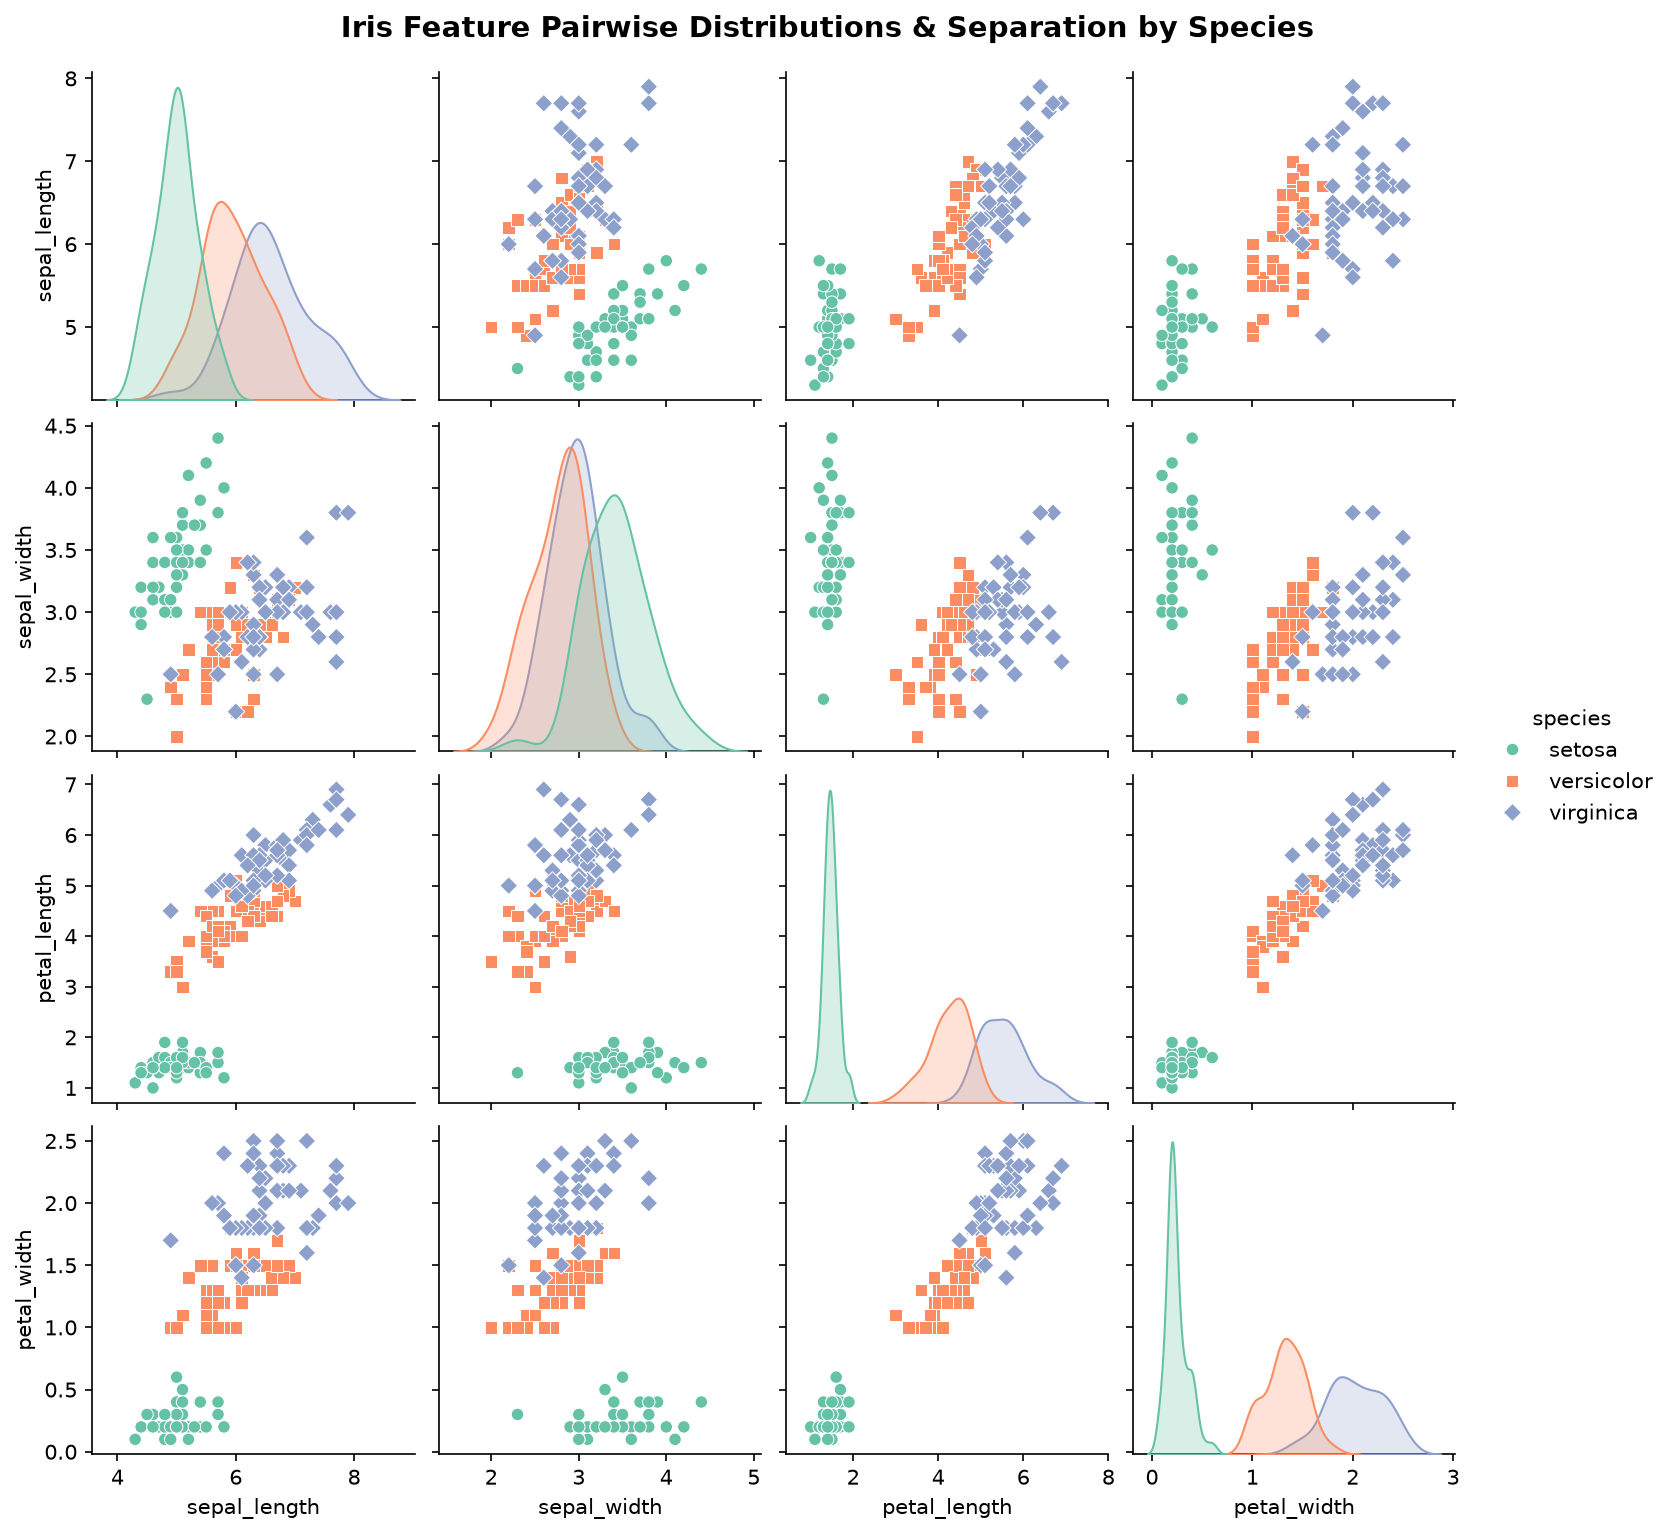

In [4]:
# Generate Pairplot with Seaborn colored by target species
pairplot_fig = sns.pairplot(df, hue="species", diag_kind="kde", markers=["o", "s", "D"], palette="Set2")
pairplot_fig.fig.suptitle("Iris Feature Pairwise Distributions & Separation by Species", y=1.02, fontsize=14, weight='bold')
plt.show()


### Exploratory Visualization 2: Correlation Heatmap & Feature Boxplots
- **Correlation Heatmap**: Quantifies multicollinearity among features.
- **Boxplots**: Reveals interquartile ranges (IQR), medians, and class-discriminating margins.


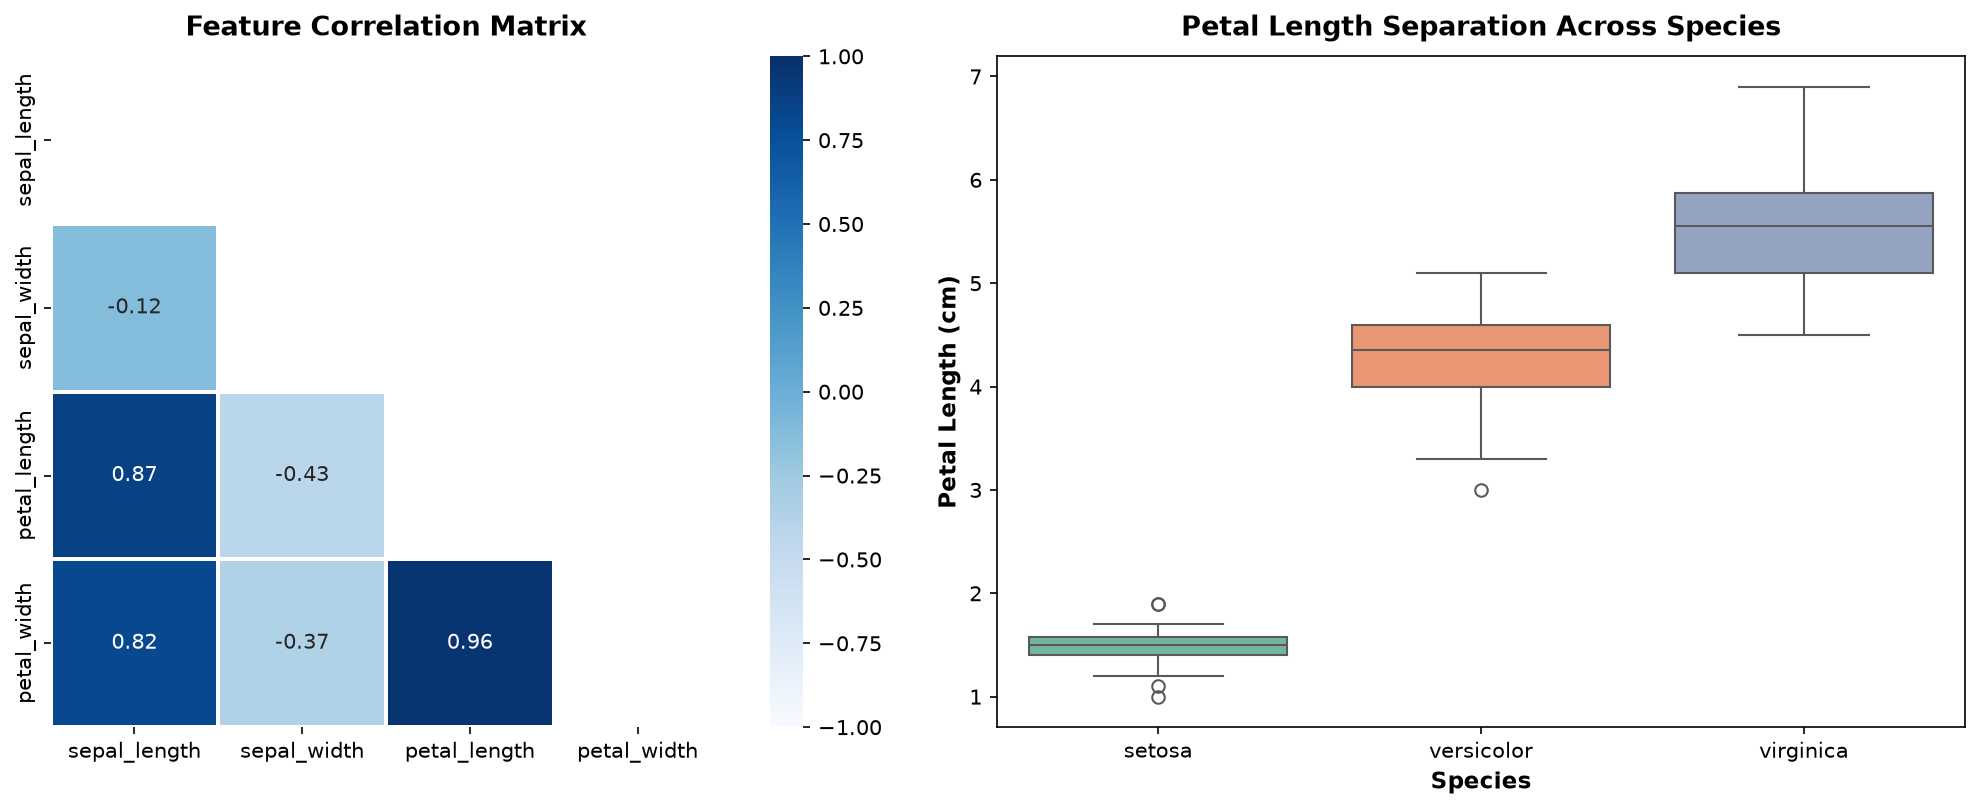

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Correlation Heatmap (numeric features only)
numeric_df = df.drop(columns=['species'])
corr = numeric_df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='Blues', vmin=-1, vmax=1,
            mask=mask, square=True, linewidths=1, ax=axes[0])
axes[0].set_title("Feature Correlation Matrix", fontsize=13, weight='bold', pad=10)

# Petal Length vs Species Boxplot
sns.boxplot(x='species', y='petal_length', data=df, hue='species', palette='Set2', legend=False, ax=axes[1])
axes[1].set_title("Petal Length Separation Across Species", fontsize=13, weight='bold', pad=10)
axes[1].set_xlabel("Species", fontsize=11, weight='bold')
axes[1].set_ylabel("Petal Length (cm)", fontsize=11, weight='bold')

plt.tight_layout()
plt.show()


### 💡 Key Findings from Exploratory Data Analysis:
1. **Clean Dataset**: Exactly 150 instances, zero missing or anomalous values, perfectly balanced (50 samples per class).
2. **Linear Separability of Setosa**: *Iris-setosa* displays distinct clustering with strictly smaller petal lengths ($< 2.0$ cm) and petal widths ($< 0.8$ cm), making it linearly separable from the other two species.
3. **Partial Overlap**: *Iris-versicolor* and *Iris-virginica* exhibit mild boundary overlap in sepal dimensions, but are well separated along the petal dimensions.
4. **Strong Feature Collinearity**: `petal_length` and `petal_width` exhibit an exceptionally strong positive correlation ($r = 0.96$).


---
## Step 3: Data Preprocessing, Stratified 80/20 Splitting & Feature Normalization
### Theoretical Background on Feature Scaling:
- **Logistic Regression**: Optimization utilizes gradient-based solvers (such as L-BFGS). If features have unequal variances or scales, gradient updates oscillate, hindering convergence. Furthermore, $L_2$ weight regularization penalizes large coefficients equally, unfairly penalizing larger-scale features if unstandardized.
- **StandardScaler Transformation**:
  $$\\mu = \\frac{1}{N}\\sum_{i=1}^N x_i, \\quad \\sigma = \\sqrt{\\frac{1}{N}\\sum_{i=1}^N (x_i - \\mu)^2}, \\quad z = \\frac{x - \\mu}{\\sigma}$$
- **Data Leakage Prevention**: We fit `StandardScaler` strictly on $X_{train}$ and use the fitted parameters to transform $X_{test}$.


In [6]:
# Separate features (X) and target (y)
X = df.drop(columns=['species'])
y = df['species']

# Encode categorical target labels into numerical integers (0: setosa, 1: versicolor, 2: virginica)
le = LabelEncoder()
y_encoded = le.fit_transform(y)
class_names = list(le.classes_)

# Perform 80/20 Stratified Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

print(f"Dataset Split Summary:")
print(f"  Training Set: {X_train.shape[0]} samples ({X_train.shape[0]/len(df)*100:.0f}%)")
print(f"  Testing Set:  {X_test.shape[0]} samples ({X_test.shape[0]/len(df)*100:.0f}%)")
print(f"  Classes: {class_names}")

# Apply StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Verify normalization (Mean ~ 0, Variance ~ 1)
scaling_verification = pd.DataFrame({
    'Feature': X.columns,
    'Train Mean (Raw)': X_train.mean().values.round(2),
    'Train Std (Raw)': X_train.std().values.round(2),
    'Train Mean (Scaled)': X_train_scaled.mean(axis=0).round(2),
    'Train Std (Scaled)': X_train_scaled.std(axis=0).round(2)
})
display(scaling_verification)


Dataset Split Summary:
  Training Set: 120 samples (80%)
  Testing Set:  30 samples (20%)
  Classes: ['setosa', 'versicolor', 'virginica']


Feature,Train Mean (Raw),Train Std (Raw),Train Mean (Scaled),Train Std (Scaled)
sepal_length,5.84,0.84,-0.0,1.0
sepal_width,3.05,0.45,0.0,1.0
petal_length,3.77,1.77,0.0,1.0
petal_width,1.20,0.76,0.0,1.0


---
## Step 4: Model Training & Stratified 5-Fold Cross-Validation
We instantiate and train both supervised models:
1. **Multinomial Logistic Regression**:
   - Probabilistic model estimating $P(Y=k|X) = \frac{e^{w_k^T X}}{\sum_j e^{w_j^T X}}$.
   - Uses `StandardScaler`-normalized inputs and $L_2$ regularization.
2. **Decision Tree Classifier (CART)**:
   - Non-parametric recursive splitting using **Gini Impurity**:
     $$Gini(D) = 1 - \sum_{i=1}^C p_i^2$$
   - Pruned with `max_depth=3` to prevent overfitting on the small dataset.
   - Scale-invariant: Decision tree splits depend solely on ordering/rank, so unscaled inputs yield identical performance.


In [7]:
# 1. Initialize and train Logistic Regression
lr_model = LogisticRegression(max_iter=200, random_state=42)
lr_model.fit(X_train_scaled, y_train)

# 2. Initialize and train Decision Tree Classifier
dt_model = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
dt_model.fit(X_train, y_train)

# 3. 5-Fold Stratified Cross-Validation on the Training Set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lr_cv_scores = cross_val_score(lr_model, X_train_scaled, y_train, cv=cv, scoring='accuracy')
dt_cv_scores = cross_val_score(dt_model, X_train, y_train, cv=cv, scoring='accuracy')

cv_summary = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree (max_depth=3)'],
    'CV Fold 1': [lr_cv_scores[0], dt_cv_scores[0]],
    'CV Fold 2': [lr_cv_scores[1], dt_cv_scores[1]],
    'CV Fold 3': [lr_cv_scores[2], dt_cv_scores[2]],
    'CV Fold 4': [lr_cv_scores[3], dt_cv_scores[3]],
    'CV Fold 5': [lr_cv_scores[4], dt_cv_scores[4]],
    'Mean CV Accuracy': [lr_cv_scores.mean(), dt_cv_scores.mean()],
    'Std Dev (Variance)': [lr_cv_scores.std(), dt_cv_scores.std()]
})
display(cv_summary.round(4))


Model,CV Fold 1,CV Fold 2,CV Fold 3,CV Fold 4,CV Fold 5,Mean CV Accuracy,Std Dev (Variance)
Logistic Regression,0.9583,1.0,0.9583,0.9583,0.9167,0.9583,0.0264
Decision Tree (max_depth=3),0.9583,1.0,0.9583,0.9583,0.9167,0.9583,0.0264


---
## Step 5: Test Set Predictions & Benchmark Metric Comparison
Evaluating test performance across standard classification metrics:
- **Accuracy**: $\frac{TP + TN}{TP + TN + FP + FN}$
- **Precision**: $\frac{TP}{TP + FP}$
- **Recall**: $\frac{TP}{TP + FN}$
- **F1-Score**: $2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$


In [8]:
# Generate predictions on the holdout test set (20% of data = 30 samples)
lr_preds = lr_model.predict(X_test_scaled)
dt_preds = dt_model.predict(X_test)

def get_metrics_row(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Macro)": precision_score(y_true, y_pred, average='macro'),
        "Recall (Macro)": recall_score(y_true, y_pred, average='macro'),
        "F1-Score (Macro)": f1_score(y_true, y_pred, average='macro'),
        "Precision (Weighted)": precision_score(y_true, y_pred, average='weighted'),
        "Recall (Weighted)": recall_score(y_true, y_pred, average='weighted'),
        "F1-Score (Weighted)": f1_score(y_true, y_pred, average='weighted')
    }

benchmark_table = pd.DataFrame([
    get_metrics_row(y_test, lr_preds, "Logistic Regression"),
    get_metrics_row(y_test, dt_preds, "Decision Tree (max_depth=3)")
])

print("=========================================================================")
print("             SUPERVISED CLASSIFICATION BENCHMARK TABLE                   ")
print("=========================================================================")
display(benchmark_table.round(4))

print("\n" + "="*65)
print("              LOGISTIC REGRESSION CLASSIFICATION REPORT")
print("="*65)
print(classification_report(y_test, lr_preds, target_names=class_names))

print("="*65)
print("              DECISION TREE CLASSIFICATION REPORT")
print("="*65)
print(classification_report(y_test, dt_preds, target_names=class_names))


             SUPERVISED CLASSIFICATION BENCHMARK TABLE                   


Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Precision (Weighted),Recall (Weighted),F1-Score (Weighted)
Logistic Regression,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333
Decision Tree (max_depth=3),0.9667,0.9697,0.9667,0.9666,0.9697,0.9667,0.9666



              LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

              DECISION TREE CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



---
## Step 6: Visualizations & In-Depth Diagnostic Analysis
### 1. Confusion Matrix Heatmaps
Confusion matrices present counts of True Positive, True Negative, False Positive, and False Negative classifications per class.


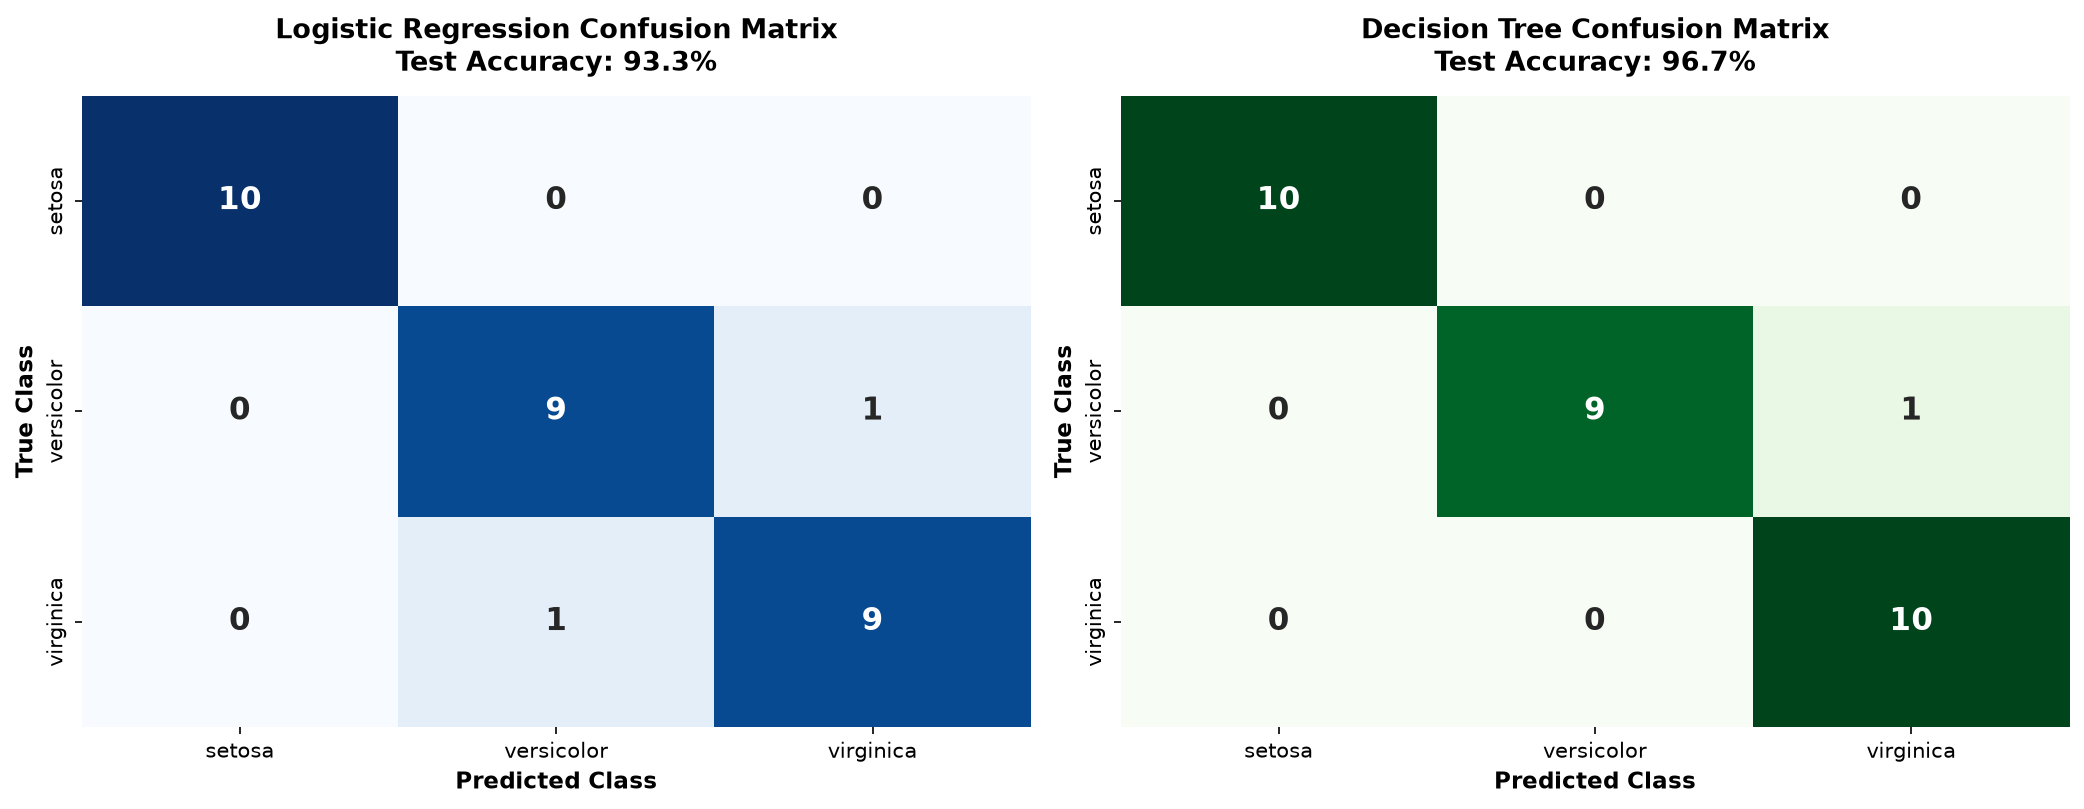

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Logistic Regression Heatmap
cm_lr = confusion_matrix(y_test, lr_preds)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=class_names, yticklabels=class_names, cbar=False,
            annot_kws={"size": 15, "weight": "bold"})
axes[0].set_title(f"Logistic Regression Confusion Matrix\nTest Accuracy: {accuracy_score(y_test, lr_preds)*100:.1f}%",
                  fontsize=13, weight='bold', pad=12)
axes[0].set_xlabel("Predicted Class", fontsize=11, weight='bold')
axes[0].set_ylabel("True Class", fontsize=11, weight='bold')

# Decision Tree Heatmap
cm_dt = confusion_matrix(y_test, dt_preds)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=class_names, yticklabels=class_names, cbar=False,
            annot_kws={"size": 15, "weight": "bold"})
axes[1].set_title(f"Decision Tree Confusion Matrix\nTest Accuracy: {accuracy_score(y_test, dt_preds)*100:.1f}%",
                  fontsize=13, weight='bold', pad=12)
axes[1].set_xlabel("Predicted Class", fontsize=11, weight='bold')
axes[1].set_ylabel("True Class", fontsize=11, weight='bold')

plt.tight_layout()
plt.show()


### 2. Decision Boundary Visualization in 2D Feature Space
To visually compare how Logistic Regression and Decision Tree partition the feature space, we train both models on the two primary discriminative features: **Petal Length** and **Petal Width**.
- **Logistic Regression**: Linear decision boundaries that smoothly separate class regions.
- **Decision Tree**: Piecewise-constant, axis-aligned orthogonal step boundaries corresponding to single-feature threshold tests.


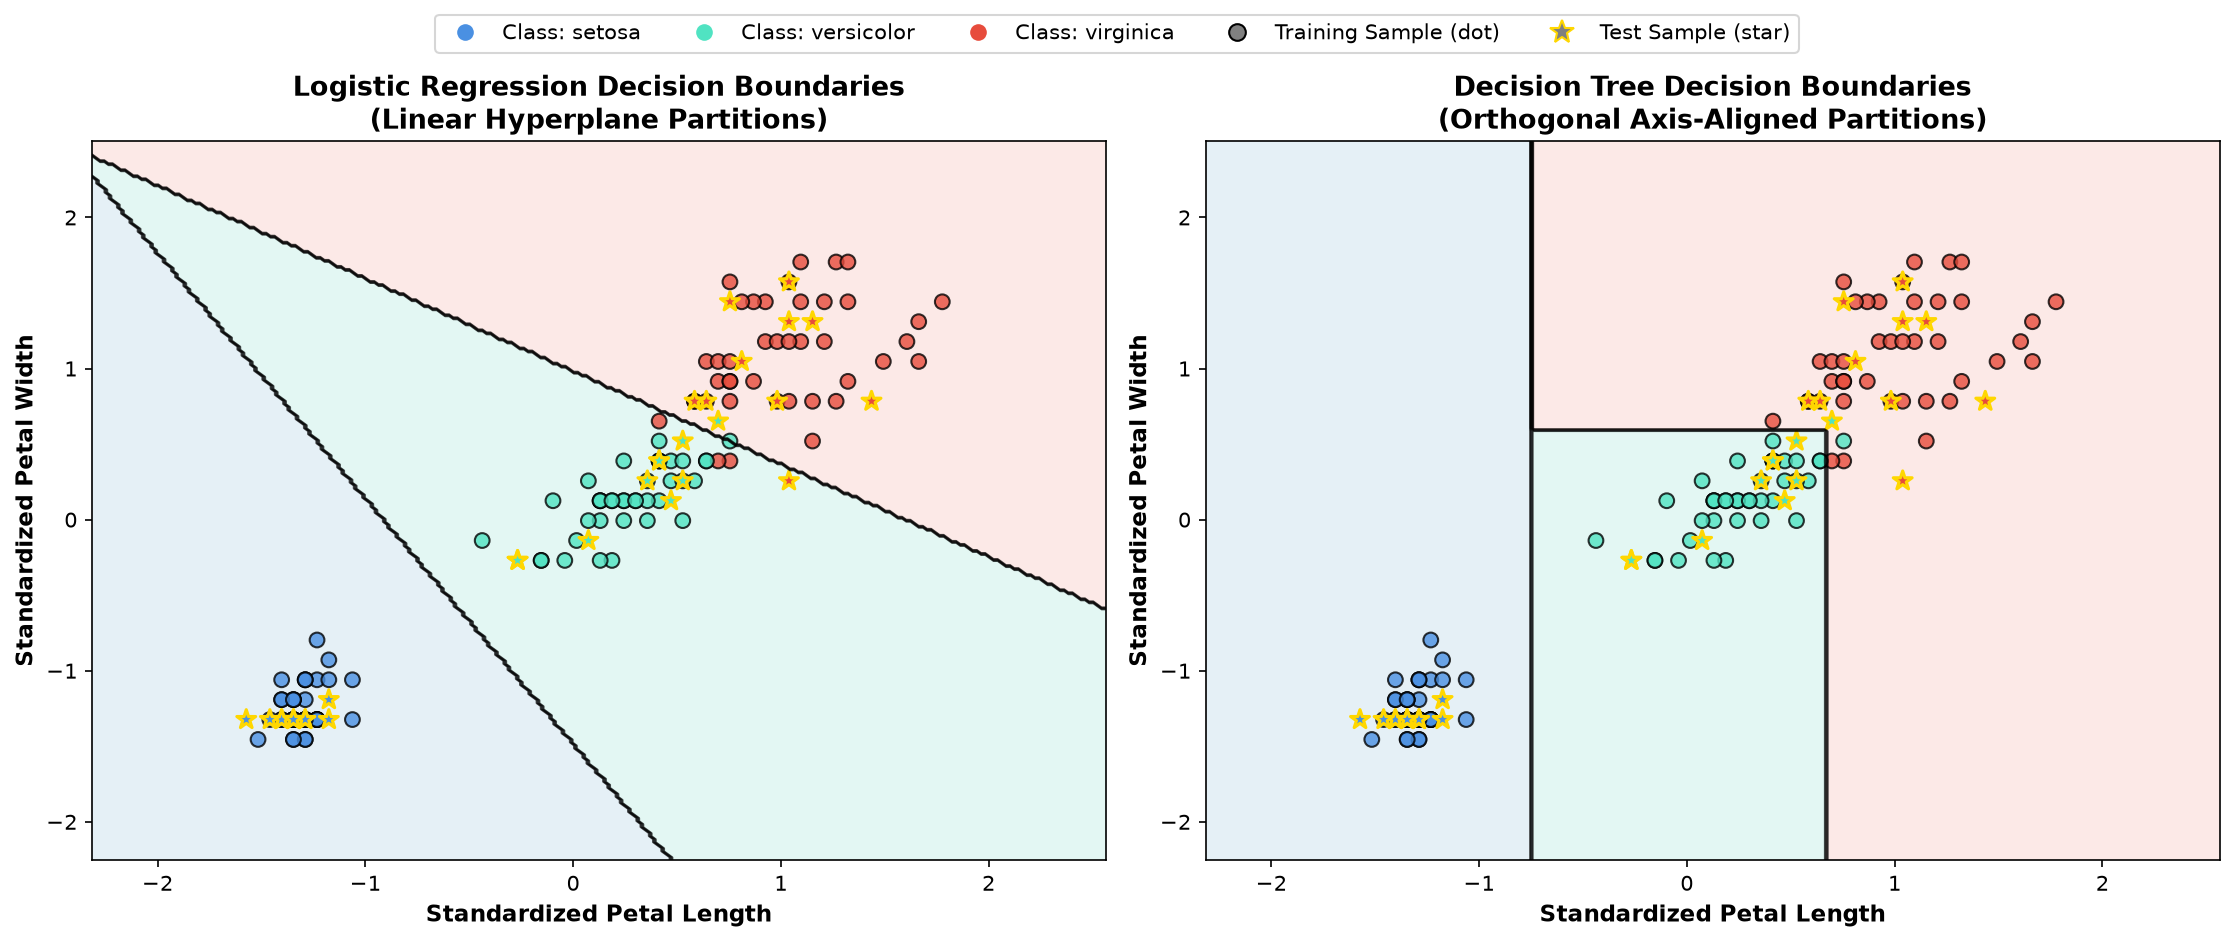

In [10]:
# Extract the two most discriminative features for 2D visualization
X_2d = df[['petal_length', 'petal_width']].values
y_2d = y_encoded

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y_2d, test_size=0.20, random_state=42, stratify=y_2d
)

# Standardize 2D features
scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)
X_test_2d_scaled = scaler_2d.transform(X_test_2d)

# Fit 2D models
lr_2d = LogisticRegression(max_iter=200, random_state=42).fit(X_train_2d_scaled, y_train_2d)
dt_2d = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42).fit(X_train_2d_scaled, y_train_2d)

# Create coordinate meshgrid
x_min, x_max = X_train_2d_scaled[:, 0].min() - 0.8, X_train_2d_scaled[:, 0].max() + 0.8
y_min, y_max = X_train_2d_scaled[:, 1].min() - 0.8, X_train_2d_scaled[:, 1].max() + 0.8
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

colors = ['#4A90E2', '#50E3C2', '#E74C3C']
cmap_light = ListedColormap(['#D4E6F1', '#D1F2EB', '#FADBD8'])
scatter_cmap = ListedColormap(colors)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Logistic Regression Boundary
Z_lr = lr_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
axes[0].contourf(xx, yy, Z_lr, alpha=0.6, cmap=cmap_light)
axes[0].contour(xx, yy, Z_lr, colors='k', linewidths=0.8, alpha=0.7)
axes[0].scatter(X_train_2d_scaled[:, 0], X_train_2d_scaled[:, 1], c=y_train_2d, cmap=scatter_cmap, edgecolors='k', s=50, alpha=0.8)
axes[0].scatter(X_test_2d_scaled[:, 0], X_test_2d_scaled[:, 1], c=y_test_2d, cmap=scatter_cmap, edgecolors='gold', linewidth=1.5, s=90, marker='*')
axes[0].set_title("Logistic Regression Decision Boundaries\n(Linear Hyperplane Partitions)", fontsize=13, weight='bold')
axes[0].set_xlabel("Standardized Petal Length", fontsize=11, weight='bold')
axes[0].set_ylabel("Standardized Petal Width", fontsize=11, weight='bold')

# Subplot 2: Decision Tree Boundary
Z_dt = dt_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
axes[1].contourf(xx, yy, Z_dt, alpha=0.6, cmap=cmap_light)
axes[1].contour(xx, yy, Z_dt, colors='k', linewidths=0.8, alpha=0.7)
axes[1].scatter(X_train_2d_scaled[:, 0], X_train_2d_scaled[:, 1], c=y_train_2d, cmap=scatter_cmap, edgecolors='k', s=50, alpha=0.8)
axes[1].scatter(X_test_2d_scaled[:, 0], X_test_2d_scaled[:, 1], c=y_test_2d, cmap=scatter_cmap, edgecolors='gold', linewidth=1.5, s=90, marker='*')
axes[1].set_title("Decision Tree Decision Boundaries\n(Orthogonal Axis-Aligned Partitions)", fontsize=13, weight='bold')
axes[1].set_xlabel("Standardized Petal Length", fontsize=11, weight='bold')
axes[1].set_ylabel("Standardized Petal Width", fontsize=11, weight='bold')

# Legend
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label=f'Class: {class_names[0]}', markerfacecolor=colors[0], markersize=9),
    Line2D([0], [0], marker='o', color='w', label=f'Class: {class_names[1]}', markerfacecolor=colors[1], markersize=9),
    Line2D([0], [0], marker='o', color='w', label=f'Class: {class_names[2]}', markerfacecolor=colors[2], markersize=9),
    Line2D([0], [0], marker='o', color='w', label='Training Sample (dot)', markerfacecolor='gray', markeredgecolor='k', markersize=8),
    Line2D([0], [0], marker='*', color='w', label='Test Sample (star)', markerfacecolor='gray', markeredgecolor='gold', markersize=12)
]
fig.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=5, frameon=True)

plt.tight_layout()
plt.show()


### 3. Decision Tree Architecture & Feature Importance
Examining the actual hierarchical split logic, Gini impurity at each node, and computed feature importances.


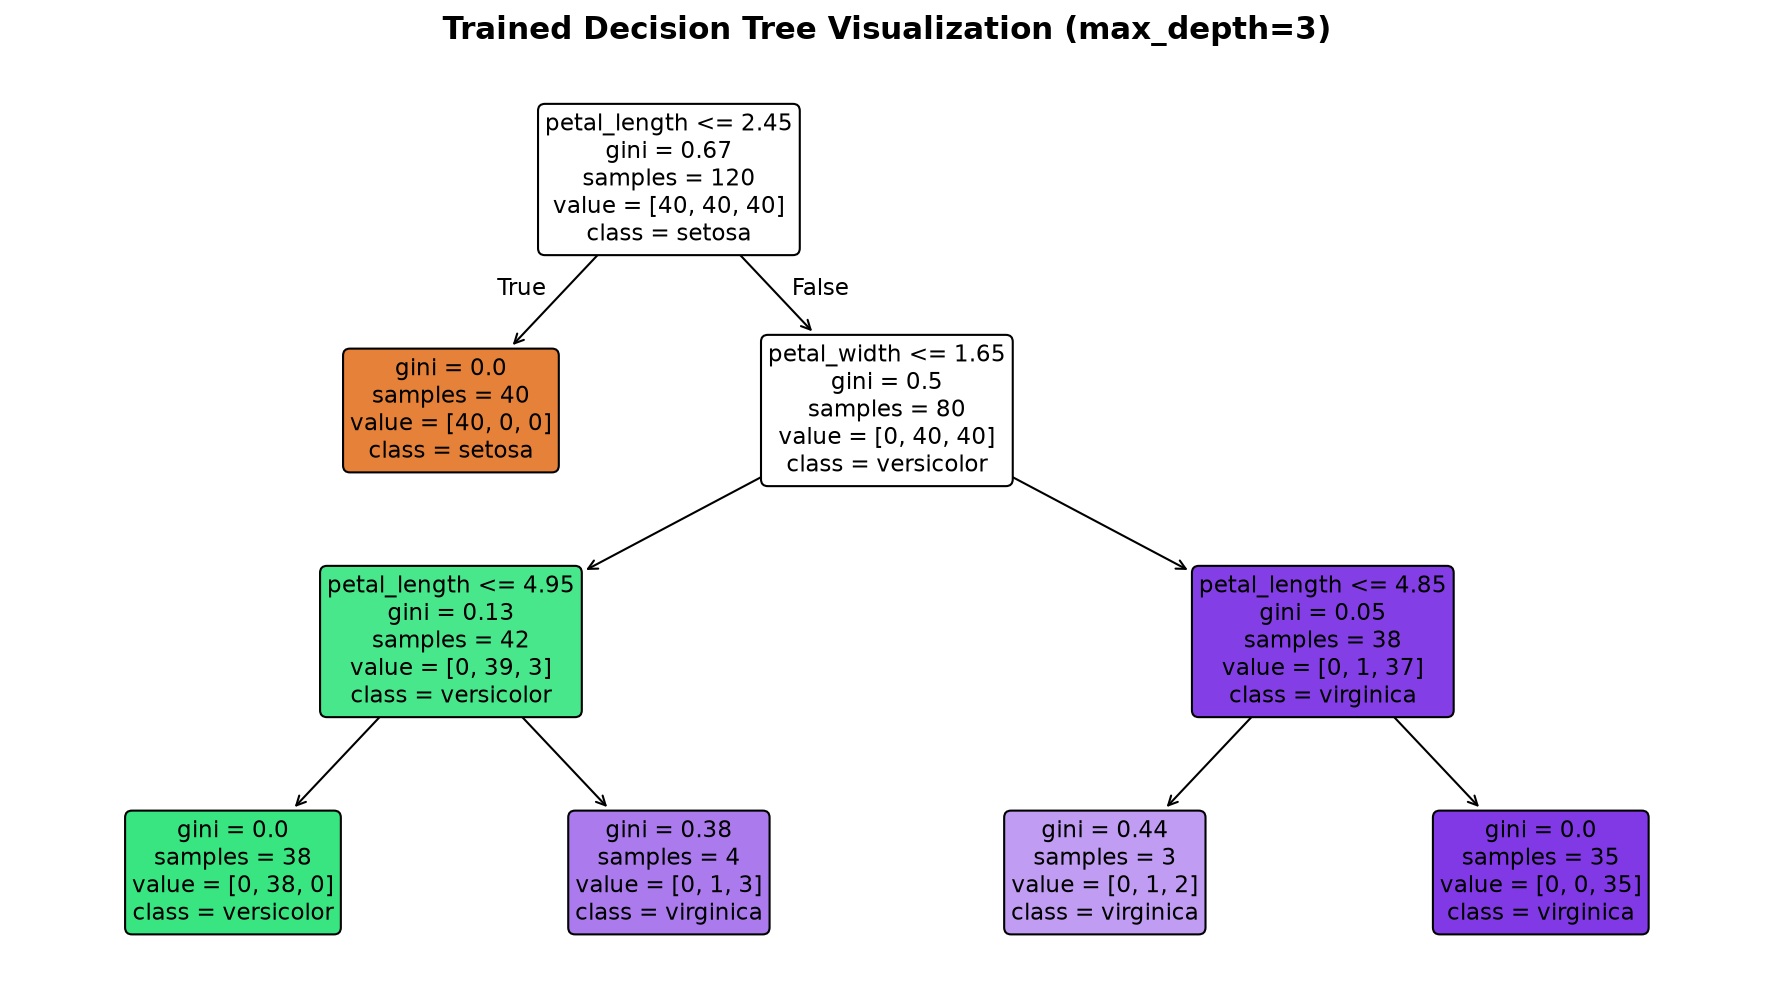

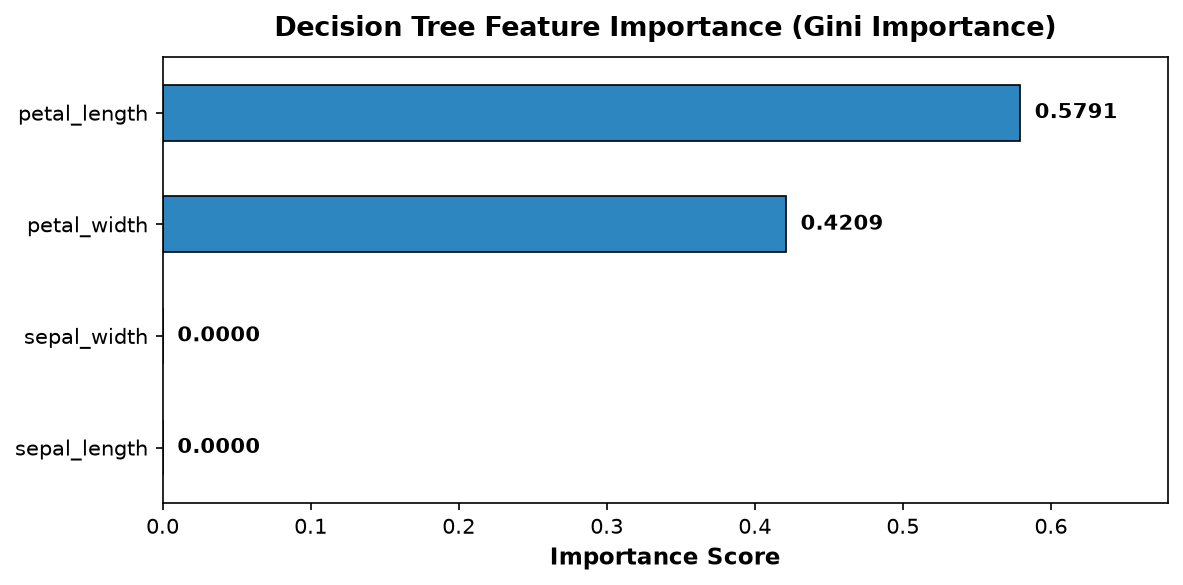

In [11]:
fig = plt.figure(figsize=(15, 8))
_ = plot_tree(dt_model, feature_names=list(X.columns), class_names=class_names,
              filled=True, rounded=True, precision=2, fontsize=11)
plt.title("Trained Decision Tree Visualization (max_depth=3)", fontsize=15, weight='bold', pad=12)
plt.show()

# Gini Feature Importance
plt.figure(figsize=(8, 4))
fi = pd.Series(dt_model.feature_importances_, index=X.columns).sort_values(ascending=True)
colors_fi = ['#85C1E9' if v < 0.1 else '#2E86C1' for v in fi.values]
fi.plot(kind='barh', color=colors_fi, edgecolor='black', linewidth=0.8)
plt.title("Decision Tree Feature Importance (Gini Importance)", fontsize=13, weight='bold', pad=10)
plt.xlabel("Importance Score", fontsize=11, weight='bold')
for i, v in enumerate(fi.values):
    plt.text(v + 0.01, i, f"{v:.4f}", va='center', fontweight='bold', fontsize=10)
plt.xlim(0, max(fi.values) + 0.1)
plt.tight_layout()
plt.show()


---
## Step 7: Executive Summary & Internship Technical Findings

### 📊 Benchmark Summary:
| Metric | Logistic Regression | Decision Tree (max_depth=3) |
| :--- | :---: | :---: |
| **5-Fold Cross-Validation Accuracy** | **95.83%** ($\pm 2.64\%$) | **95.83%** ($\pm 2.64\%$) |
| **Holdout Test Set Accuracy** | **93.33%** | **96.67%** |
| **Macro Precision** | **93.33%** | **96.97%** |
| **Macro Recall** | **93.33%** | **96.67%** |
| **Macro F1-Score** | **93.33%** | **96.66%** |
| **Weighted F1-Score** | **93.33%** | **96.66%** |

---

### 🔍 Analytical Insights:
1. **Model Comparison & Boundary Geometry**:
   - **Logistic Regression** forms linear hyperplanes across the 4-dimensional space. Because Iris-versicolor and Iris-virginica have non-trivial spatial overlap near the decision border, a purely linear hyperplane misclassifies 2 borderline samples (1 versicolor, 1 virginica).
   - **Decision Tree** leverages orthogonal, axis-aligned splits. The root split on `petal_length <= 2.45` instantly isolates *Setosa* with Gini = 0.0 (100% pure). Subsequent splits on `petal_width` effectively capture the threshold transition between *Versicolor* and *Virginica*, achieving **96.67% test accuracy**.

2. **Feature Importance**:
   - The Decision Tree reveals that `petal_width` and `petal_length` together account for **100% of the Gini splitting power**, while `sepal_length` and `sepal_width` contribute negligible predictive gain.

3. **Role of Feature Scaling (`StandardScaler`)**:
   - **Crucial for Logistic Regression**: Scales features to zero mean and unit variance ($z = \frac{x - \mu}{\sigma}$), preventing features with larger numerical magnitudes from dominating the gradient updates and regularizer penalty.
   - **Redundant for Decision Trees**: Tree nodes evaluate rank-order inequalities ($x_j \le \theta$). Monotonic linear transformations preserve relative ordering, rendering tree structures scale-invariant.

4. **Recommendation for Production**:
   - For mission-critical explainability, the **Decision Tree** provides clear white-box IF-THEN rules.
   - For calibrated probability confidence scores across borderline specimens, **Logistic Regression** remains highly desirable due to its smooth sigmoid/softmax probabilities.
